# Bài 1 – Dự báo giá nhà bằng Hồi quy tuyến tính (Linear Regression)
Dữ liệu: `USA_Housing.csv` (Kaggle) – http://teacher.uelstore.com/dataset/USA_Housing.csv

## Bước 1: Import thư viện

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## Bước 2: Đọc và khám phá dữ liệu
Tải file CSV về cùng thư mục với notebook (hoặc đọc trực tiếp từ URL).

In [89]:
df = pd.read_csv('USA_Housing.csv')
# df = pd.read_csv('http://teacher.uelstore.com/dataset/USA_Housing.csv')
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   str    
dtypes: float64(6), str(1)
memory usage: 499.6 KB


In [91]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [92]:
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='str')

### Biểu đồ hỗ trợ phân tích

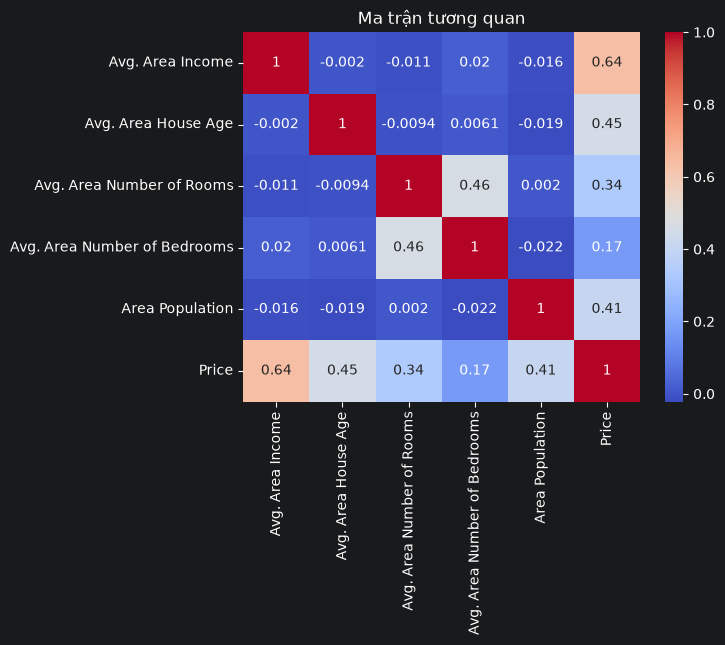

In [93]:
sns.heatmap(df.drop(columns='Address').corr(), annot=True, cmap='coolwarm')
plt.title('Ma trận tương quan')
plt.show()

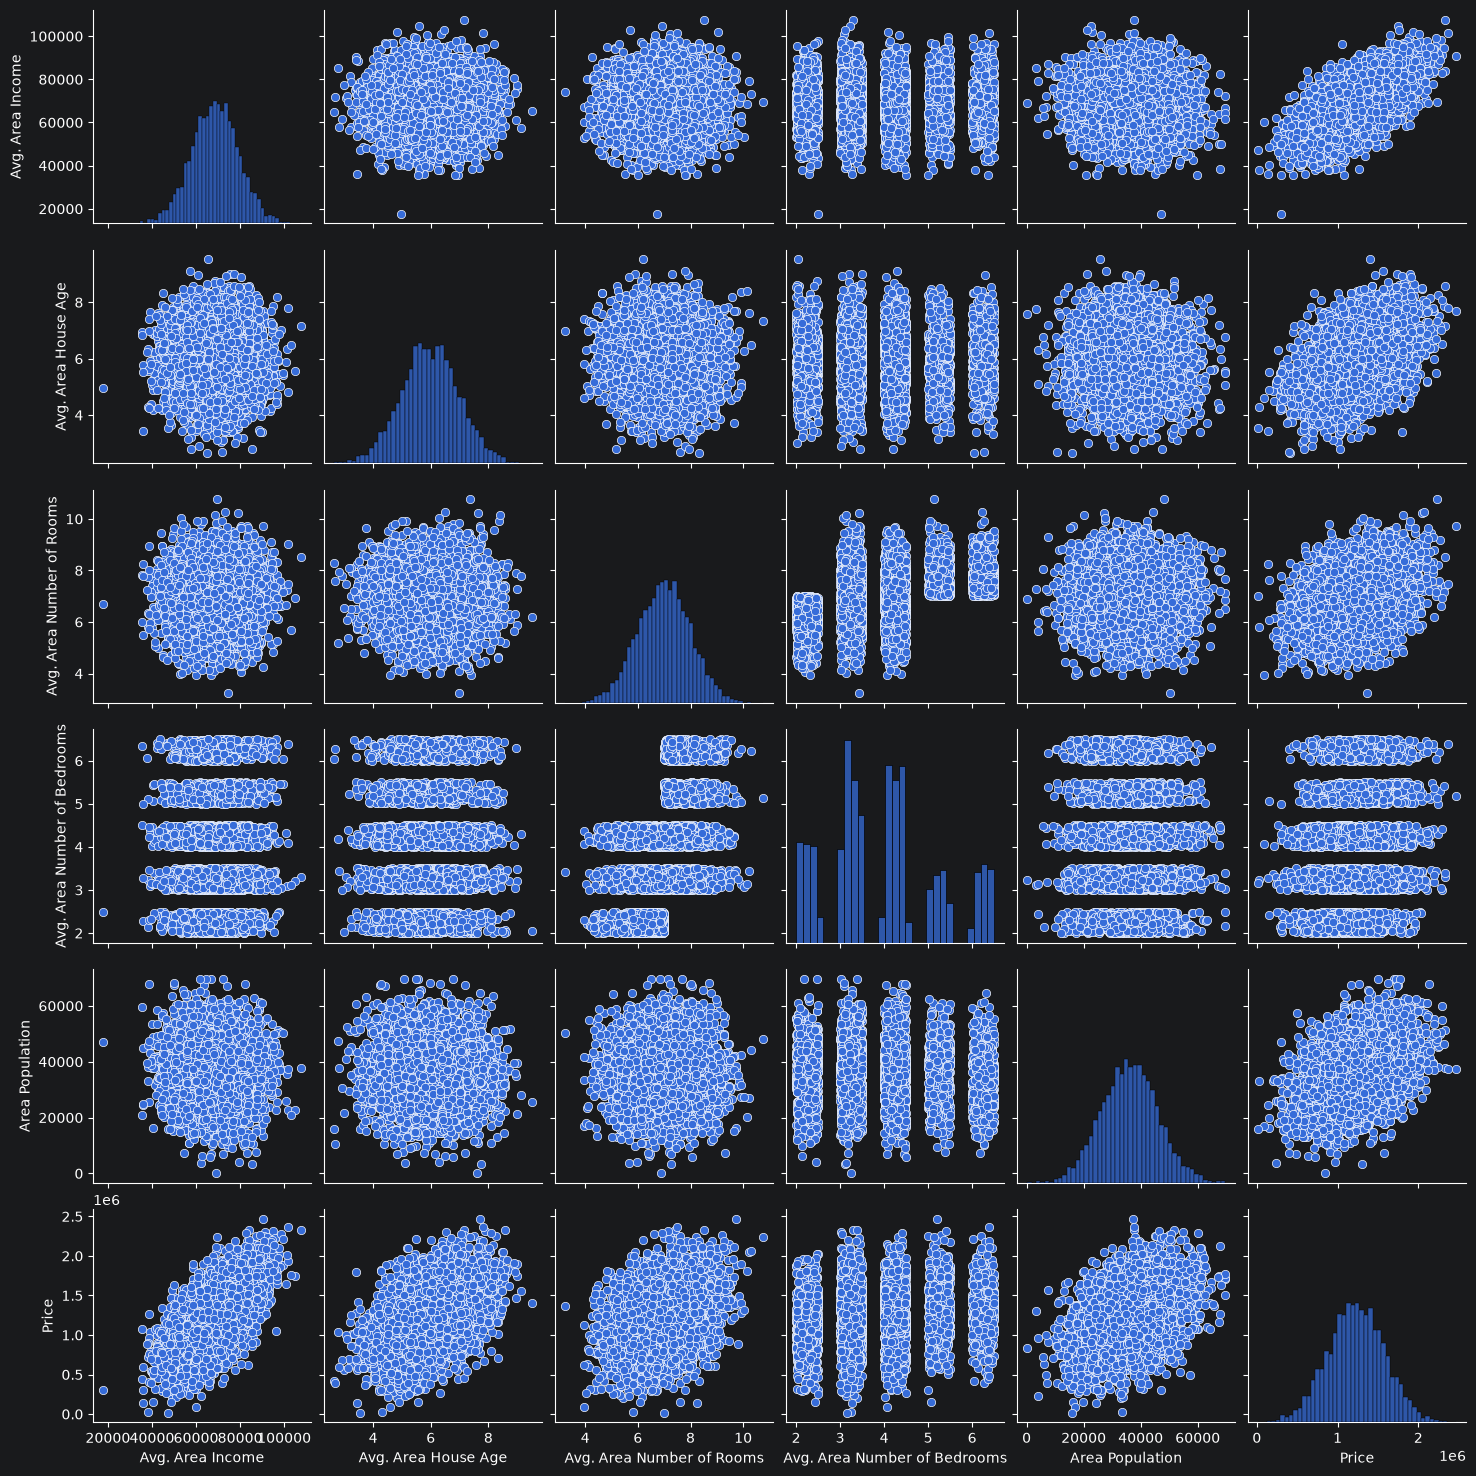

In [94]:
sns.pairplot(df.drop(columns='Address'))
plt.show()

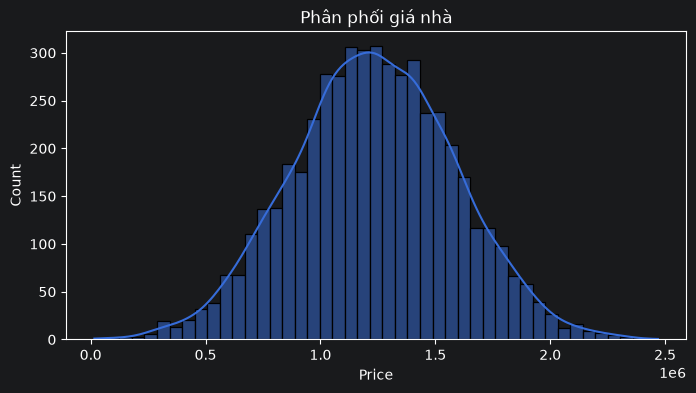

In [95]:
plt.figure(figsize=(8,4))
sns.histplot(df['Price'], kde=True)
plt.title('Phân phối giá nhà')
plt.show()

Cột `Price` có tương quan nhiều nhất với `Avg. Area Income`; các cột khác cũng ảnh hưởng ở mức khác nhau.

## Bước 3: Chia dữ liệu và train mô hình
Loại cột `Address` (dạng text, hồi quy tuyến tính không dùng).

In [96]:
X = df[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
        'Avg. Area Number of Bedrooms', 'Area Population']]
y = df['Price']

In [97]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

In [98]:
from sklearn.linear_model import LinearRegression
lm = LinearRegression()
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 21.57,165453.04,120499.84, 1999.79, 15.34]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Avg. Area Income','Avg. Area House Age','Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms','Area Population']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.64e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


## Bước 4: Dự báo

In [99]:
predictions = lm.predict(X_test)
predictions[:5]

array([1257919.729097  ,  822112.41884192, 1740669.05865498,
        972452.1291749 ,  993422.26329309])

In [100]:
# Dự báo 1 căn nhà lấy từ tập test
pre1 = lm.predict(X_test.iloc[[0]])
print("kết quả 1 =", pre1)

kết quả 1 = [1257919.729097]


In [101]:
# Dự báo 1 căn nhà nhập tay
pre2 = lm.predict(pd.DataFrame([[66774.995817, 5.717143, 7.795215, 4.320000, 36788.980327]], columns=X.columns))
print("kết quả 2 =", pre2)

kết quả 2 = [1257919.71744578]


## Bước 5: Đánh giá mô hình

In [102]:
print('Intercept:', lm.intercept_)
coeff_df = pd.DataFrame(lm.coef_, X.columns, columns=['Coefficient'])
coeff_df

Intercept: -2640441.3997815847


,Coefficient
Avg. Area Income,21.566696
Avg. Area House Age,165453.042478
Avg. Area Number of Rooms,120499.839093
Avg. Area Number of Bedrooms,1999.785336
Area Population,15.340604


In [103]:
from sklearn import metrics
print('MAE :', metrics.mean_absolute_error(y_test, predictions))
print('MSE :', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))
print('R2  :', metrics.r2_score(y_test, predictions))

MAE : 81305.23300085826
MSE : 10100187858.865685
RMSE: 100499.69083965226
R2  : 0.921171916540217


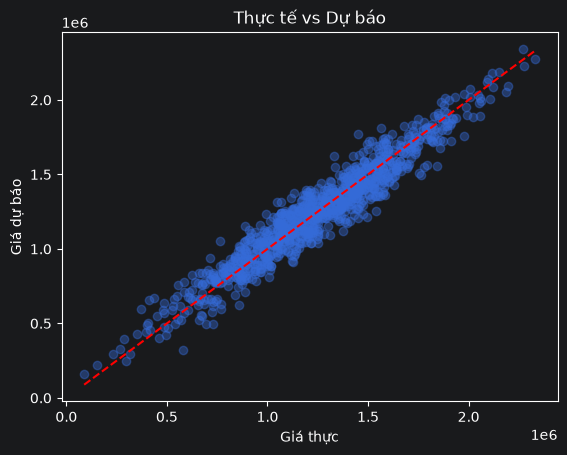

In [104]:
plt.scatter(y_test, predictions, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Giá thực'); plt.ylabel('Giá dự báo'); plt.title('Thực tế vs Dự báo')
plt.show()

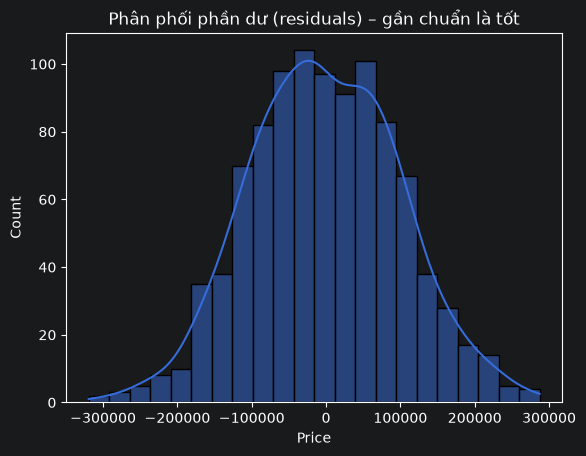

In [105]:
sns.histplot(y_test - predictions, kde=True)
plt.title('Phân phối phần dư (residuals) – gần chuẩn là tốt')
plt.show()

## Bước 6: Lưu và tái sử dụng mô hình

In [106]:
import pickle
modelname = "housingmodel.zip"
pickle.dump(lm, open(modelname, 'wb'))

In [107]:
trainedmodel = pickle.load(open(modelname, 'rb'))
pd.DataFrame(trainedmodel.coef_, X.columns, columns=['Coefficient'])

,Coefficient
Avg. Area Income,21.566696
Avg. Area House Age,165453.042478
Avg. Area Number of Rooms,120499.839093
Avg. Area Number of Bedrooms,1999.785336
Area Population,15.340604


In [108]:
prediction = trainedmodel.predict(pd.DataFrame([[66774.995817, 5.717143, 7.795215, 4.320000, 36788.980327]], columns=X.columns))
print("kết quả =", prediction)

kết quả = [1257919.71744578]
